In [1]:
import astropy.io.fits as fits
import numpy as np
import matplotlib.pyplot as plt

In [2]:
tab = fits.open("./cfht_hr_20230131/2696300s.fits")

In [3]:
tab[0].header

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                    8 / array data type                                
NAXIS   =                    0 / number of array dimensions                     
EXTEND  =                    T                                                  
NEXTEND =                    2 / Number of extensions                           
COMMENT This file contains the following extensions: UniformWavelength,         
COMMENT UniformVelocity                                                         
FILENAME= '2696300o'           / filename anticipated by fitspipe server        
PATHNAME= '/data/sessions/spirou/21BQ20-Jan11' / Original directory name at acqu
DATE    = '2022-01-12T12:58:23' / UTC Date of file creation                     
HSTTIME = 'Wed Jan 12 02:58:23 HST 2022' / Local time in Hawaii                 
IMAGESWV= 'DetCom-SPIRou v1.20 svn 13907 (compiled Aug 25 2020)' / Image creatio
IMAGELBV= 'CFHT libdetcom v1

## https://www.cfht.hawaii.edu/Instruments/SPIRou/FileStructure.php

In [4]:
import JW_lib

In [5]:
spec_obs = JW_lib.Spectrum(tab[1].data["Wave"] / 1e3, tab[1].data["FluxAB"])

In [6]:
def fix_spec(spec_obs):
    flx = spec_obs.flux
    ind_nan = np.where(np.isfinite(flx) == False)
    ind_val = np.where(np.isfinite(flx) == True)
    flx[ind_nan] = np.interp(spec_obs.wavelength[ind_nan], spec_obs.wavelength[ind_val], spec_obs.flux[ind_val])

    spec_obs.flux = flx
    return(spec_obs)

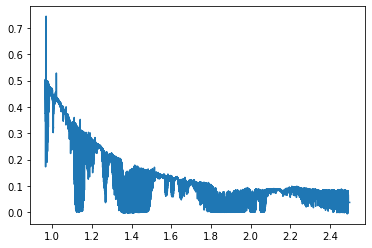

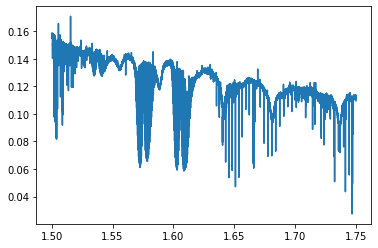

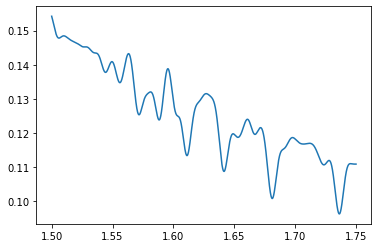

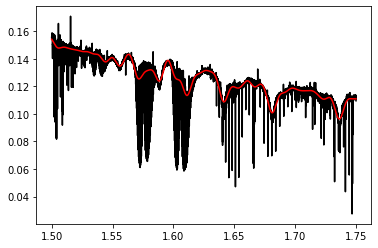

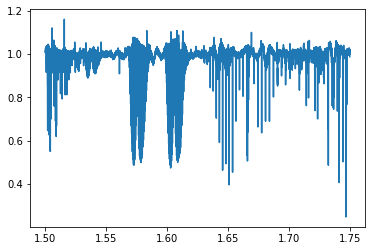

In [7]:
spec_obs = fix_spec(spec_obs)

spec_obs.pltSpec()

wav_min = 1.5
wav_max = 1.75

spec_obs_chunk = spec_obs.getChunk(wav_min, wav_max)
spec_obs_chunk.pltSpec()

spec_obs_chunk_low_pass = spec_obs_chunk.applyHighPassFilter(pass_type="low")
spec_obs_chunk_low_pass.pltSpec()

plt.plot(spec_obs_chunk.wavelength, spec_obs_chunk.flux, color="black")
plt.plot(spec_obs_chunk_low_pass.wavelength, spec_obs_chunk_low_pass.flux, color="red")

spec_h_test = spec_obs_chunk_low_pass.copy()
spec_h_test.flux = spec_obs_chunk.flux / spec_obs_chunk_low_pass.flux
# spec_h_test.writeSpec(file_name="spec_h_test.txt")
spec_h_test.pltSpec()

In [8]:
# import astropy.io.ascii
# spec_h_test = JW_lib.readSpec(file_name="spec_h_test.txt")

In [9]:
spec_h_test.spec_reso = 100e3
spec_h_new = spec_h_test.copy().resampleSpectoSpectrograph(pixel_sampling=5.0)

In [10]:
def getContinuumLowHighValue(spec, low=0.8, high=1.1):
    ind = np.where((spec.flux > high) | (spec.flux < low))
    spec_tmp = spec.copy()
    spec_tmp.flux[ind] = np.median(spec.flux)
    cont = spec_tmp.applyHighPassFilter(pass_type="low", order = 5, cutoff = 1000.0)
    return(cont.flux, spec_tmp.flux)
    
def getContinuumLowHighPercentile(spec, low=0.8, high=0.95):
    per_low = np.percentile(spec.flux, low)
    per_high = np.percentile(spec.flux, high)
    ind = np.where((spec.flux > per_high) | (spec.flux < per_low))
    spec_tmp = spec.copy()
    spec_tmp.flux[ind] = np.median(spec.flux)
    cont = spec_tmp.applyHighPassFilter(pass_type="low", order = 5, cutoff = 1000.0)
    return(cont.flux, spec_tmp.flux)

In [11]:
def norm_spec(spec):
    cont, spec_tmp = getContinuumLowHighValue(spec, low=0.8, high=1.2)
    spec.flux = spec.flux / cont
    cont, spec_tmp = getContinuumLowHighValue(spec, low=0.98, high=1.05)
    spec.flux = spec.flux / cont
    cont, spec_tmp = getContinuumLowHighValue(spec, low=1.0, high=1.02)
    spec.flux = spec.flux / cont
    return(spec)

In [12]:
spec_h_new = spec_h_new.getChunk(1.52, 1.55)
spec_h_new = norm_spec(spec_h_new)

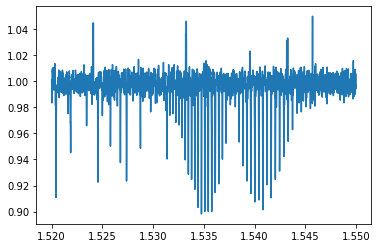

In [13]:
spec_h_new.pltSpec()
spec_h_new.writeSpec(file_name="spec_h_norm.txt")